# RM2 · Complex numbers and rotations, the MRI way

**Part:** Math refresher · **Reading time:** ~20 min · **Pass 1 overview:** [What MRI measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · **Refreshers you may want:** [RM1 ODEs](RM1_ODEs_for_MRI.ipynb)

You already know complex numbers. This refresher only covers how MRI *uses* them: the transverse
magnetization is stored as one complex number, precession is multiplication by $e^{-i\omega t}$, and the
signal from a voxel is a **sum of many phasors** — which is why signals decay when spins dephase ($T_2^*$).
The second half covers 3D rotation matrices, the cross product in the Bloch equation, and the
sign convention that confuses everyone: MRI precession is a **left-handed (clockwise)** rotation.

## Learning goals

1. Write the transverse magnetization as $M_{xy}=M_x+iM_y=|M_{xy}|e^{i\phi}$ and read magnitude and phase from it.
2. Explain why multiplying by $e^{-i\omega t}$ is a clockwise rotation and why multiplying phasors adds their phases.
3. Predict the magnitude of a sum of many phasors with spread-out phases, and connect this to $T_2^*$ signal loss and to spin echoes.
4. Use the right-handed rotation matrices $R_x, R_y, R_z$, know that their order matters, and use the cross product geometrically.
5. Explain why $d\vec M/dt=\gamma\vec M\times\vec B$ is a left-handed rotation about $\vec B$ and how `mri_tools` implements it.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $i=\sqrt{-1}$ | imaginary unit (engineers write $j$; Python writes `1j`) | – | |
| $c=a+ib=Ae^{i\phi}$ | a complex number in Cartesian and polar form | – | |
| $a,\ b$ | real and imaginary parts | – | |
| $A=\lvert c\rvert$ | magnitude | – | |
| $\phi$ | phase (angle), measured counter-clockwise from the real axis | rad | |
| $\vec M=[M_x,M_y,M_z]^T$ | magnetization vector | normalized ($M_0=1$) | physically A/m |
| $M_{xy}=M_x+iM_y$ | transverse magnetization as a complex number | normalized | |
| $\omega,\ f$ | angular / ordinary frequency, $\omega=2\pi f$ | rad/s, Hz | |
| $\Delta f$ | off-resonance frequency of a spin | Hz | 1–100 Hz from field inhomogeneity |
| $t$ | time | s | |
| $T_2,\ T_2',\ T_2^*$ | transverse decay, dephasing, effective decay time constants; $1/T_2^*=1/T_2+1/T_2'$ | s | |
| $\Gamma$ | half-width at half-maximum of a Lorentzian frequency spread | Hz | $T_2'=1/(2\pi\Gamma)$ |
| $N_s$ | number of spins (isochromats) summed | – | |
| $R_x(\alpha), R_y(\alpha), R_z(\alpha)$ | right-handed rotation matrices by angle $\alpha$ | – | `mt.Rx` etc. (here $R$ = rotation, not acceleration) |
| $\alpha$ | rotation angle | rad | |
| $\hat n$ | unit vector along a rotation axis | – | |
| $\vec\Omega$ | angular-velocity vector (axis × rate) | rad/s | |
| $\vec B$, $B_0$ | magnetic field; main field along $z$ | T | 1.5 / 3 T |
| $\gamma,\ \bar\gamma$ | gyromagnetic ratio (angular / in Hz) | rad s⁻¹ T⁻¹, Hz/T | $2.675\times10^8$, 42.58 MHz/T |
| $\omega_0=\gamma B_0$ | Larmor angular frequency | rad/s | $2\pi\cdot127.7$ MHz at 3 T |
| $\theta$ | flip angle | rad (or °) | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Thirty-second recap

$$c = a + ib = A\,e^{i\phi},\qquad e^{i\phi}=\cos\phi+i\sin\phi,\qquad A=|c|=\sqrt{a^2+b^2},\qquad \phi=\operatorname{atan2}(b,a).$$

In words: a complex number is a 2D vector (real part along $x$, imaginary part along $y$); its polar form gives length $A$ and
angle $\phi$ measured counter-clockwise from the positive real axis.

> **⚠️ Common confusion:** the phase is **not** simply $\tan^{-1}(b/a)$ — that formula cannot tell $1+i$ from $-1-i$.
> Use the two-argument arctangent $\operatorname{atan2}(b,a)$, which is what `np.angle` does; it returns values in $(-\pi,\pi]$.

> **⚠️ Common confusion — $i$ vs $j$:** physicists and this series write $i=\sqrt{-1}$. Electrical engineers (and
> many RF/hardware papers) write $j$ because $i$ is current. Python uses `1j`. Same number.

| operation | Cartesian | polar | geometric meaning |
|---|---|---|---|
| conjugate $c^*$ | $a-ib$ | $Ae^{-i\phi}$ | mirror at real axis (phase negated) |
| product $c_1c_2$ | (expand) | $A_1A_2\,e^{i(\phi_1+\phi_2)}$ | **multiply lengths, add angles** |
| $\lvert c\rvert^2$ | $a^2+b^2$ | $A^2$ | $=c\,c^*$ |
| $c\,e^{i\alpha}$ | | $Ae^{i(\phi+\alpha)}$ | rotate by $\alpha$ counter-clockwise |

In [2]:
c = -1 - 1j
print("np.abs(c)   =", np.abs(c))
print("np.angle(c) =", np.angle(c), "rad =", np.rad2deg(np.angle(c)), "deg   (atan2: correct quadrant)")
print("arctan(b/a) =", np.rad2deg(np.arctan(c.imag / c.real)), "deg   (wrong quadrant!)")
c1, c2 = 2 * np.exp(1j * np.deg2rad(30)), 0.5 * np.exp(1j * np.deg2rad(45))
print("c1*c2: |.| =", np.abs(c1 * c2), " angle =", np.rad2deg(np.angle(c1 * c2)), "deg  (= 30 + 45)")

np.abs(c)   = 1.4142135623730951
np.angle(c) = -2.356194490192345 rad = -135.0 deg   (atan2: correct quadrant)
arctan(b/a) = 45.0 deg   (wrong quadrant!)
c1*c2: |.| = 1.0  angle = 74.99999999999999 deg  (= 30 + 45)


The product has magnitude $2\times0.5=1$ and phase $30°+45°=75°$: multiplication = scaling + rotation.

## 2. Transverse magnetization as a complex number

The magnetization $\vec M=[M_x,M_y,M_z]^T$ has a **longitudinal** part $M_z$ (along $B_0$) and a
**transverse** part $(M_x,M_y)$, which is what the receive coil detects. Because the transverse part is a 2D vector
that rotates, MRI packs it into one complex number:

$$M_{xy} = M_x + i\,M_y = |M_{xy}|\,e^{i\phi}.$$

In words: the magnitude $|M_{xy}|$ is "how much signal", the **phase** $\phi$ is "which direction it currently points in the $x$–$y$ plane".
Where: $M_x$, $M_y$ = transverse components (normalized, $M_0=1$), $\phi$ = phase [rad].

- **Magnitude images** (what radiologists mostly look at) display $|M_{xy}|$ for each voxel.
- **Phase images** display $\phi$; they encode field inhomogeneity, flow velocity, temperature, susceptibility…
- The receiver really does measure both: **quadrature detection** produces two signals 90° apart that become the real and imaginary parts
  ([B5 RF system](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)).

## 3. Precession is multiplication by $e^{-i\omega t}$

In a field $B_0$ along $z$, $M_{xy}$ obeys $dM_{xy}/dt=-i\omega_0M_{xy}$ ([RM1](RM1_ODEs_for_MRI.ipynb)), so

$$M_{xy}(t) = M_{xy}(0)\,e^{-i\omega_0 t},\qquad \phi(t)=\phi(0)-\omega_0t.$$

In words: the length stays constant, the phase **decreases** linearly in time, i.e. the vector turns
**clockwise** when you look down from $+z$. Where: $\omega_0=\gamma B_0$ = Larmor angular frequency [rad/s] (at 3 T: $\omega_0=2\pi\cdot127.7\times10^6$ rad/s).

Because $e^{-i\omega_1t_1}e^{-i\omega_2t_2}=e^{-i(\omega_1t_1+\omega_2t_2)}$, consecutive precession periods simply
**add phase**. With a time-varying frequency $\omega(t)$ the accumulated phase is the integral

$$\phi(t)=\phi(0)-\int_0^t\omega(\tau)\,d\tau.$$

where $\tau$ is the dummy integration variable [s]. This single fact is the root of spatial encoding: gradients make $\omega$ depend on position, so the phase records position
([F1 Spatial encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb)).

Multiplication by $e^{i\alpha}$ is the same as the 2D rotation matrix acting on $[M_x,M_y]^T$:

rotation matrix:       [0.41999927 0.74404342]
complex multiplication: [0.4199992715892207, 0.7440434206849248]


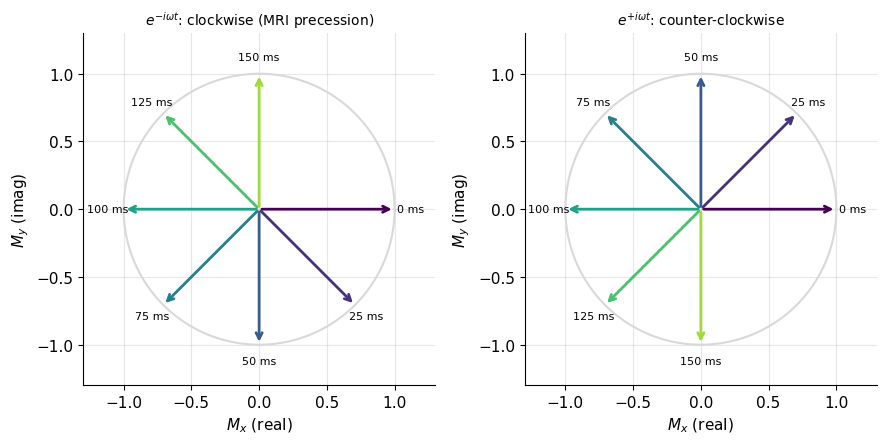

In [3]:
alpha = np.deg2rad(40)
M = np.array([0.8, 0.3])                       # [Mx, My]
R2 = np.array([[np.cos(alpha), -np.sin(alpha)], [np.sin(alpha), np.cos(alpha)]])  # right-handed 2D rotation
z = (M[0] + 1j * M[1]) * np.exp(1j * alpha)
print("rotation matrix:      ", R2 @ M)
print("complex multiplication:", [z.real, z.imag])

f = 5.0                                        # [Hz] slow, so we can watch it
t = np.linspace(0, 0.15, 7)                    # [s]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
for a_, sign, name in [(ax[0], -1, r"$e^{-i\omega t}$: clockwise (MRI precession)"), (ax[1], +1, r"$e^{+i\omega t}$: counter-clockwise")]:
    zz = np.exp(sign * 1j * 2 * np.pi * f * t)
    th = np.linspace(0, 2 * np.pi, 200); a_.plot(np.cos(th), np.sin(th), color="0.85")
    for k, zk in enumerate(zz):
        a_.annotate("", xy=(zk.real, zk.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=plt.cm.viridis(k / len(zz)), lw=2))
        a_.text(1.12 * zk.real, 1.12 * zk.imag, f"{t[k]*1e3:.0f} ms", ha="center", va="center", fontsize=8)
    a_.set_aspect("equal"); a_.set_xlim(-1.3, 1.3); a_.set_ylim(-1.3, 1.3)
    a_.set_xlabel(r"$M_x$ (real)"); a_.set_ylabel(r"$M_y$ (imag)"); a_.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

Both give the same vector, and the snapshots (dark = early, yellow = late) show $e^{-i\omega t}$ turning from $+x$ towards $-y$.

> **🧭 Intuition — the rotating frame in one line:** to remove the fast Larmor rotation, multiply by the
> opposite rotation: $M_{xy}^{rot}(t)=M_{xy}(t)\,e^{+i\omega_0t}$. Anything left over (rotation at a few Hz)
> is **off-resonance**. The scanner's receiver does exactly this multiplication electronically ("demodulation").

## 4. Summing phasors: dephasing, $T_2^*$ and echoes

A voxel contains billions of spins, and the coil receives their **sum**. If every spin has its own small
off-resonance $\Delta f_j$ (because the field is never perfectly uniform), each is a phasor $e^{-i2\pi\Delta f_jt}$ in the rotating
frame, and the net signal is

$$s(t)\;\propto\;\frac{1}{N_s}\sum_{j=1}^{N_s}e^{-i2\pi\Delta f_j t}.$$

In words: at $t=0$ all phasors point the same way and add up fully; as time passes they fan out, partly cancel,
and the sum shrinks — even though **no single spin has lost any magnetization**. Where: $N_s$ = number of spins, $\Delta f_j$ = off-resonance of spin $j$ [Hz].

The shape of the decay is the (inverse) Fourier transform of the frequency distribution
([RM5 Fourier pairs](RM5_Fourier_Pairs_and_Sampling.ipynb)):

- **Lorentzian** spread with half-width $\Gamma$ [Hz] → exponential decay $e^{-t/T_2'}$ with $T_2'=1/(2\pi\Gamma)$. This is why dephasing is modelled with a time constant $T_2'$ and $1/T_2^*=1/T_2+1/T_2'$.
- **uniform** spread over $\pm\Delta$ → a sinc-shaped decay (as across a voxel in a linear gradient).

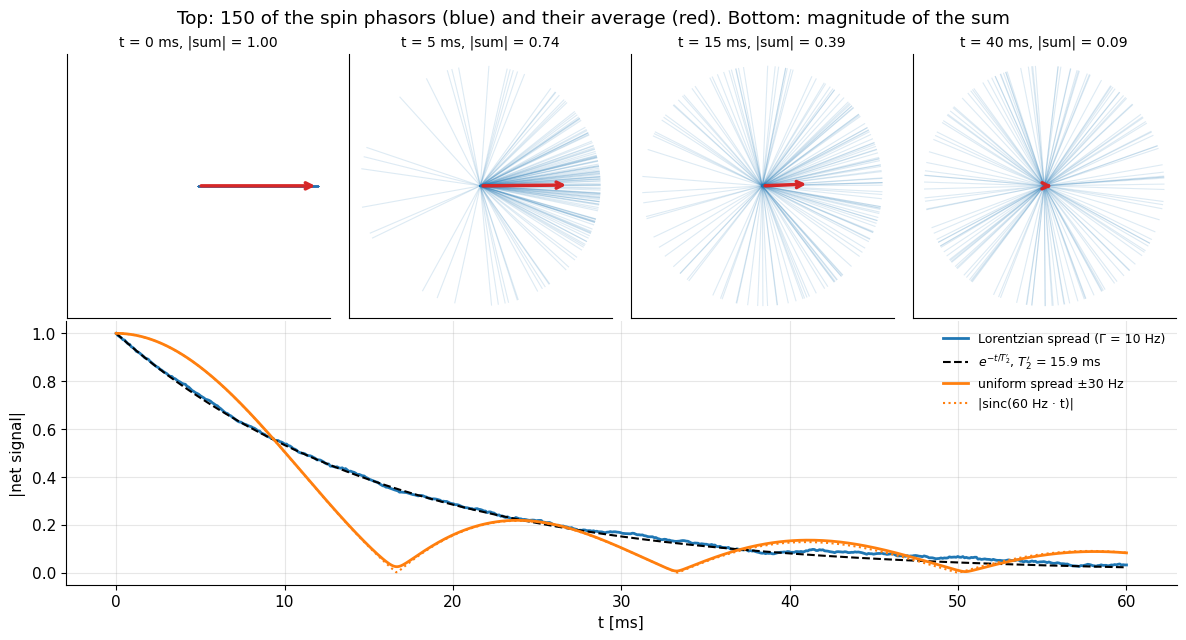

In [4]:
rng = np.random.default_rng(1)
Ns = 2000
t = np.linspace(0, 60e-3, 600)                       # [s]
Gamma = 10.0                                         # Lorentzian half-width [Hz]  -> T2' = 1/(2 pi Gamma) = 15.9 ms
df_lor = Gamma * rng.standard_cauchy(Ns)             # Lorentzian (Cauchy) distributed off-resonances [Hz]
df_uni = rng.uniform(-30, 30, Ns)                    # uniform spread, +-30 Hz
s_lor = np.exp(-1j * 2 * np.pi * np.outer(t, df_lor)).mean(axis=1)
s_uni = np.exp(-1j * 2 * np.pi * np.outer(t, df_uni)).mean(axis=1)
T2p = 1 / (2 * np.pi * Gamma)

fig = plt.figure(figsize=(12, 6.5))
for k, tk in enumerate([0, 5e-3, 15e-3, 40e-3]):     # phasor "fans" at four times
    a_ = fig.add_subplot(2, 4, k + 1)
    ph = np.exp(-1j * 2 * np.pi * df_lor[:150] * tk)
    for p in ph:
        a_.plot([0, p.real], [0, p.imag], color="C0", alpha=0.15, lw=0.8)
    S = np.exp(-1j * 2 * np.pi * df_lor * tk).mean()
    a_.annotate("", xy=(S.real, S.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C3", lw=2.5))
    a_.set_aspect("equal"); a_.set_xlim(-1.1, 1.1); a_.set_ylim(-1.1, 1.1); a_.set_xticks([]); a_.set_yticks([])
    a_.set_title(f"t = {tk*1e3:.0f} ms, |sum| = {abs(S):.2f}", fontsize=10)
a_ = fig.add_subplot(2, 1, 2)
a_.plot(t * 1e3, np.abs(s_lor), lw=2, label=f"Lorentzian spread (Γ = {Gamma:g} Hz)")
a_.plot(t * 1e3, np.exp(-t / T2p), "k--", label=f"$e^{{-t/T_2'}}$, $T_2'$ = {T2p*1e3:.1f} ms")
a_.plot(t * 1e3, np.abs(s_uni), lw=2, label="uniform spread ±30 Hz")
a_.plot(t * 1e3, np.abs(np.sinc(60 * t)), ":", color="C1", label="|sinc(60 Hz · t)|")
a_.set_xlabel("t [ms]"); a_.set_ylabel("|net signal|"); a_.legend(fontsize=9)
fig.suptitle("Top: 150 of the spin phasors (blue) and their average (red). Bottom: magnitude of the sum")
plt.tight_layout(); plt.show()

The red arrow (net signal) shrinks as the blue phasors fan out; the Lorentzian spread gives the dashed exponential, the uniform spread the sinc.

**Spin echo in phasor language.** Dephasing from *static* field differences is reversible. A 180° pulse about
$x$ mirrors every phasor, $M_{xy}\to M_{xy}^*$, i.e. every phase $\phi_j\to-\phi_j$. The spins keep precessing at
their own rate, so the fast ones (which were ahead) are now behind by exactly as much, and at $t=TE$ (twice the
time of the 180°) all phases are zero again: an **echo**. Only the irreversible $T_2$ loss remains.

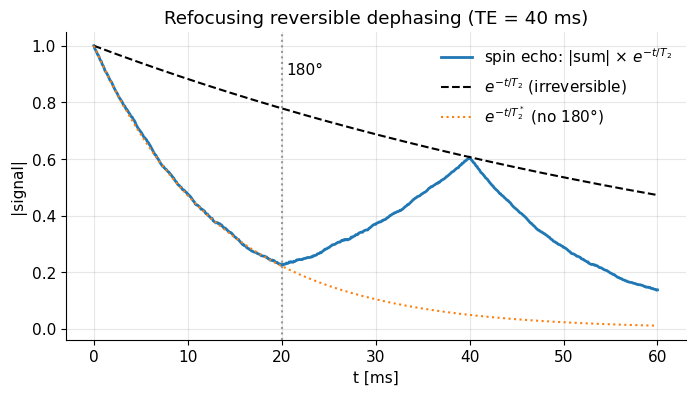

In [5]:
TE = 40e-3; T2 = 80e-3                                   # [s]
t = np.linspace(0, 60e-3, 601)                           # [s]
phase = -2 * np.pi * np.outer(t, df_lor)                 # accumulated phase of each spin
after = t > TE / 2
# after the 180 deg pulse at TE/2: phase -> -phase(TE/2), then keeps accumulating at the same rate
phase[after] = -(-2 * np.pi * TE / 2 * df_lor) - 2 * np.pi * np.outer(t[after] - TE / 2, df_lor)
s_se = np.exp(1j * phase).mean(axis=1) * np.exp(-t / T2)
plt.plot(t * 1e3, np.abs(s_se), lw=2, label="spin echo: |sum| × $e^{-t/T_2}$")
plt.plot(t * 1e3, np.exp(-t / T2), "k--", label=r"$e^{-t/T_2}$ (irreversible)")
plt.plot(t * 1e3, np.exp(-t / T2 - t / T2p), ":", label=r"$e^{-t/T_2^*}$ (no 180°)")
plt.axvline(TE / 2 * 1e3, color="0.6", ls=":"); plt.text(TE / 2 * 1e3 + 0.5, 0.9, "180°")
plt.xlabel("t [ms]"); plt.ylabel("|signal|"); plt.title("Refocusing reversible dephasing (TE = 40 ms)"); plt.legend(); plt.show()

The signal decays with $T_2^*$, then regrows to touch the $T_2$ curve exactly at $t=TE$: conjugating the phasors undid the dephasing. Details in [D3 Gradient and spin echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb).

## 5. Rotations in 3D

For RF pulses we need rotations about $x$ or $y$, which mix $M_z$ with the transverse components — complex numbers are no longer enough.
The standard **right-handed** rotation matrices by angle $\alpha$ [rad] are (`mt.Rx`, `mt.Ry`, `mt.Rz`):

$$R_x(\alpha)=\begin{bmatrix}1&0&0\\0&\cos\alpha&-\sin\alpha\\0&\sin\alpha&\cos\alpha\end{bmatrix},\quad
R_y(\alpha)=\begin{bmatrix}\cos\alpha&0&\sin\alpha\\0&1&0\\-\sin\alpha&0&\cos\alpha\end{bmatrix},\quad
R_z(\alpha)=\begin{bmatrix}\cos\alpha&-\sin\alpha&0\\\sin\alpha&\cos\alpha&0\\0&0&1\end{bmatrix}.$$

In words: each leaves its own axis untouched and turns the other two coordinates by $\alpha$, **counter-clockwise when viewed from the tip of the axis**
(right-hand rule: thumb along the axis, fingers curl in the direction of positive $\alpha$).

Facts you will use:
- The columns of $R$ are where the $x$, $y$, $z$ unit vectors end up.
- $R^{-1}=R^T=R(-\alpha)$, $\det R = 1$, and rotations preserve length ($|R\vec M|=|\vec M|$).
- **Order matters**: $R_xR_y\neq R_yR_x$. Applying $R_1$ first and then $R_2$ is the product $R_2R_1$ (rightmost acts first).
- A rotation about any unit axis $\hat n$: Rodrigues' formula, `mt.rotation_matrix(n, alpha)`.

> **⚠️ Common confusion:** $R$ here means rotation matrix. In other chapters $R$ is the acceleration factor or a resistance — see [Notation](../reference/Notation_and_Symbols.ipynb).

In [6]:
a90 = np.pi / 2
z_hat = np.array([0.0, 0.0, 1.0])
print("Rx(90°) z =", np.round(mt.Rx(a90) @ z_hat, 3), "  (right-handed: z -> -y)")
print("Ry(90°) z =", np.round(mt.Ry(a90) @ z_hat, 3), "  (right-handed: z -> +x)")
print("Ry Rx z   =", np.round(mt.Ry(a90) @ mt.Rx(a90) @ z_hat, 3), "  (x first, then y)")
print("Rx Ry z   =", np.round(mt.Rx(a90) @ mt.Ry(a90) @ z_hat, 3), "  (y first, then x)  -> order matters")
print("Rodrigues about x equals Rx:", np.allclose(mt.rotation_matrix([1, 0, 0], 0.7), mt.Rx(0.7)))
print("length preserved:", np.linalg.norm(mt.rotation_matrix([1, 2, 3], 1.1) @ np.array([0.3, -0.5, 0.8])), "=", np.linalg.norm([0.3, -0.5, 0.8]))

Rx(90°) z = [ 0. -1.  0.]   (right-handed: z -> -y)
Ry(90°) z = [1. 0. 0.]   (right-handed: z -> +x)
Ry Rx z   = [ 0. -1.  0.]   (x first, then y)
Rx Ry z   = [ 1. -0.  0.]   (y first, then x)  -> order matters
Rodrigues about x equals Rx: True
length preserved: 0.9899494936611668 = 0.9899494936611666


Two 90° rotations in different order send $\vec z$ to different places — keep track of the order in which RF pulses are applied.

## 6. The cross product, geometrically

$$\vec a\times\vec b = \begin{bmatrix}a_yb_z-a_zb_y\\ a_zb_x-a_xb_z\\ a_xb_y-a_yb_x\end{bmatrix},\qquad |\vec a\times\vec b| = |\vec a||\vec b|\sin\angle(\vec a,\vec b).$$

In words: the result is **perpendicular to both** $\vec a$ and $\vec b$, its length is largest when they are perpendicular and zero when they are parallel,
and its direction follows the right-hand rule ($\hat x\times\hat y=\hat z$, $\hat y\times\hat z=\hat x$, $\hat z\times\hat x=\hat y$; swapping the order flips the sign).

In the Bloch equation $d\vec M/dt=\gamma\,\vec M\times\vec B$ this means:

- the change of $\vec M$ is always perpendicular to $\vec M$ → its **length is conserved** (pure rotation);
- it is also perpendicular to $\vec B$ → the angle between $\vec M$ and $\vec B$ is conserved, so $\vec M$ moves on a **cone around $\vec B$**;
- if $\vec M\parallel\vec B$ nothing happens (equilibrium along $B_0$ is stable without RF).

Example: $\vec M=\hat x$, $\vec B=B_0\hat z$: $\;d\vec M/dt=\gamma B_0(\hat x\times\hat z)=-\gamma B_0\,\hat y$. The tip starts moving from $+x$ towards **$-y$** —
clockwise seen from $+z$.

## 7. Why MRI precession is left-handed

A rigid **right-handed** rotation with angular-velocity vector $\vec\Omega$ (direction = axis by the right-hand rule, length = rate in rad/s) moves a vector as
$d\vec M/dt=\vec\Omega\times\vec M$. Compare with Bloch:

$$\frac{d\vec M}{dt}=\gamma\,\vec M\times\vec B = (-\gamma\vec B)\times\vec M\quad\Rightarrow\quad\vec\Omega=-\gamma\vec B.$$

In words: for $\gamma>0$ (protons) the rotation vector points **opposite** to $\vec B$, i.e. the rotation is right-handed about $-\vec B$ = **left-handed
(clockwise) about $\vec B$**, at rate $\gamma|\vec B|$. Where: $\gamma$ = gyromagnetic ratio [rad s⁻¹ T⁻¹], $\vec B$ in T.
For nuclei with negative $\gamma$ (e.g. ¹²⁹Xe) it is the other way round. The physical origin — a magnetic moment that is also an angular momentum,
torque $=\vec\mu\times\vec B$ — is in [RP3 Precession and torque](RP3_Precession_and_Torque.ipynb).

`mri_tools` therefore implements a Bloch rotation as an ordinary right-handed rotation with the angle negated:
`mt.bloch_rotate(M, dt, B)` = `mt.rotation_matrix(B, -gamma*|B|*dt) @ M`. The same rule applies to RF pulses:
in the rotating frame an RF field along $+x$ tips $\vec M$ from $+z$ towards **$+y$** (left-handed about $x$).

In [7]:
B = np.array([0.0, 0.0, 1.0e-6])                 # 1 uT along z (rotating frame, tiny so the angle is easy)
dt = 1e-3                                        # [s]
angle = mt.GAMMA * np.linalg.norm(B) * dt        # rotation angle [rad]
M = np.array([1.0, 0.0, 0.0])
print(f"angle = gamma |B| dt = {np.rad2deg(angle):.1f} deg")
print("mt.bloch_rotate:           ", np.round(mt.bloch_rotate(M, dt, B), 4), "  (My < 0: clockwise)")
print("rotation_matrix(B, -angle):", np.round(mt.rotation_matrix(B, -angle) @ M, 4))
print("right-handed would give:   ", np.round(mt.rotation_matrix(B, +angle) @ M, 4))

# RF pulse: B1 along +x in the rotating frame, 90 deg flip, starting from equilibrium +z
T_rf = 1e-3
B1 = mt.b1_for_flip(np.pi / 2, T_rf)             # amplitude of a 1-ms hard 90 deg pulse [T]
print(f"\n90° hard pulse, B1 = {B1*1e6:.2f} uT for 1 ms along +x:",
      np.round(mt.bloch_rotate([0, 0, 1], T_rf, [B1, 0, 0]), 4), " -> M ends on +y")

angle = gamma |B| dt = 15.3 deg
mt.bloch_rotate:            [ 0.9644 -0.2643  0.    ]   (My < 0: clockwise)
rotation_matrix(B, -angle): [ 0.9644 -0.2643  0.    ]
right-handed would give:    [0.9644 0.2643 0.    ]

90° hard pulse, B1 = 5.87 uT for 1 ms along +x: [0. 1. 0.]  -> M ends on +y


`bloch_rotate` matches the right-handed matrix with the **negated** angle, and a 90° RF pulse along $+x$ puts $\vec M$ on $+y$.

> **⚠️ Common confusion:** textbooks differ here. Some draw precession counter-clockwise, or put $\vec M$ on $-y$ after a $90°_x$
> pulse, or define $M_{xy}=M_x-iM_y$. Physics does not change — only signs in formulas do. This series always uses
> $d\vec M/dt=\gamma\vec M\times\vec B$, $M_{xy}=M_x+iM_y$, $M_{xy}(t)=M_{xy}(0)e^{-i\omega t}$, exactly as `mri_tools`.

## Where this shows up in MRI

| Idea | Where it is used |
|---|---|
| $M_{xy}=M_x+iM_y$, magnitude and phase images | [A2 Bloch equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb), [C2 Signal equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| precession $e^{-i\omega t}$, rotating frame, demodulation | [A1 Spin physics](../pass2_deep_dive/A1_Spin_Physics.ipynb), [A2 Bloch equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb), [B5 RF system](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| phase = integral of frequency → spatial encoding | [F1 Spatial encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb), [F2 K-space](../pass2_deep_dive/F2_K-space.ipynb) |
| sum of phasors, $T_2^*$, $T_2'$ | [A3 In vivo spin physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb), [D3 Gradient and spin echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb), [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb) |
| rotation matrices, RF flip, left-handedness | [A2 Bloch equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb), [E1 RF pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb), [RP3 Precession and torque](RP3_Precession_and_Torque.ipynb) |

Compact formula sheet: [MRI math concepts](../reference/MRI_Math_Concepts.ipynb).

## Key takeaways

- $M_{xy}=M_x+iM_y=|M_{xy}|e^{i\phi}$: magnitude = signal strength, phase = direction in the transverse plane. Use `np.angle` (atan2), not $\tan^{-1}(b/a)$.
- Multiplying complex numbers multiplies lengths and **adds phases**; $e^{-i\omega t}$ is a clockwise rotation, $e^{+i\omega t}$ counter-clockwise.
- Phase is the time integral of frequency; this is how gradients write position into the signal.
- A voxel's signal is a sum of phasors. A spread of frequencies makes them fan out and cancel: Lorentzian spread → $e^{-t/T_2'}$; static dephasing can be undone by a 180° pulse (spin echo).
- $R_x,R_y,R_z$ are right-handed, length-preserving, and do **not** commute.
- $\vec a\times\vec b$ is perpendicular to both; in Bloch it makes $\vec M$ move on a cone about $\vec B$ with constant length.
- $\gamma\vec M\times\vec B=(-\gamma\vec B)\times\vec M$: precession is left-handed (clockwise) about $\vec B$ for protons; `mt.bloch_rotate` uses angle $\to-$angle.

## Check your understanding

1. $M_{xy}=-0.3+0.4i$. What are $|M_{xy}|$ and the phase in degrees?
<details><summary>Answer</summary>

$|M_{xy}|=\sqrt{0.09+0.16}=0.5$; phase $=\operatorname{atan2}(0.4,-0.3)\approx126.9°$ (second quadrant; $\tan^{-1}(0.4/-0.3)=-53.1°$ would be wrong).

</details>

2. A spin is 10 Hz off-resonance. What phase (in degrees) has it accumulated after 25 ms in the rotating frame, and in which direction?
<details><summary>Answer</summary>

$\phi=-2\pi\cdot10\cdot0.025=-\pi/2$, i.e. $-90°$: a quarter turn clockwise (for a positive off-resonance).

</details>

3. Why does the signal from a voxel decay even if no individual spin loses magnetization?
<details><summary>Answer</summary>

The coil measures the vector sum of all spins. With different precession frequencies their phases spread out, the phasors partly cancel, and the magnitude of the sum decreases ($T_2'$ dephasing, contributing to $T_2^*$).

</details>

4. Using the cross product, which way does $\vec M=\hat y$ start to move in $\vec B=B_0\hat z$?
<details><summary>Answer</summary>

$d\vec M/dt=\gamma B_0(\hat y\times\hat z)=+\gamma B_0\hat x$: from $+y$ towards $+x$, which is again clockwise seen from $+z$.

</details>

5. Is $R_x(90°)R_y(90°)=R_y(90°)R_x(90°)$? What does that mean for two RF pulses about different axes?
<details><summary>Answer</summary>

No, 3D rotations do not commute (the demo shows different results). The order in which RF pulses (or pulse and precession) are applied changes the final magnetization.

</details>

---
*New refresher written for this adaptation of P. Larson, "Principles of MRI" (MIT License); see references below.*
*References: T. Needham, *Visual Complex Analysis* (Oxford University Press);
D. G. Nishimura, *Principles of Magnetic Resonance Imaging*;
M. H. Levitt, *Spin Dynamics: Basics of Nuclear Magnetic Resonance* (Wiley) — careful discussion of the precession sign;
E. M. Haacke, R. W. Brown, M. R. Thompson, R. Venkatesan, *Magnetic Resonance Imaging: Physical Principles and Sequence Design* (Wiley).*